# LAB 08 — Pretrained Transformers & BERT Fine-Tuning Experiments

Notebook này triển khai đầy đủ các thực nghiệm từ **Mục 13 đến Mục 22** của đề bài LAB 08:
1. **Experiment 1 (Mục 14):** Pretrained Transformer (`google/bert_uncased_L-2_H-128_A-2`) vs Transformer train from scratch trên cùng tập IMDb.
2. **Experiment 2 (Mục 15):** Feature Extraction (Frozen encoder) vs Fine-tuning toàn bộ.
3. **Experiment 3 (Mục 16):** Ảnh hưởng của lượng dữ liệu huấn luyện (`10%, 25%, 50%, 100%`) và vẽ đường cong `data_efficiency.png`.
4. **Experiment 4 (Mục 17):** Ảnh hưởng của Max Sequence Length $T \in \{64, 128, 256\}$ (thời gian, bộ nhớ CPU và liên hệ $O(T^2)$).
5. **Experiment 5 (Mục 18):** Đánh giá **Domain Shift** từ Movie Reviews (IMDb) sang Product Reviews (Amazon) và Financial News.
6. **Application & Confidence Analysis (Mục 19, 20, 21):** Đánh giá đầy đủ Accuracy / Precision / Recall / F1, vẽ `confusion_matrix.png`, phân tích `confidence_analysis.png`, xuất `results.csv` và trích xuất các mẫu lỗi thực tế cho `error_analysis.md`.

In [1]:
import copy
import gc
import json
import os
import platform
import random
import re
import sys
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

LAB08_DIR = Path("/Users/user/NLP/LAB08")
sys.path.insert(0, str(LAB08_DIR))

from pretrained_classification import (
    DEFAULT_MODEL_NAME,
    FromScratchTransformerClassifier,
    PretrainedSentimentClassifier,
    count_parameters,
    load_tokenizer,
)

# Reproducibility settings (Mục 23)
SEED = 42
def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)
torch.set_num_threads(4)
device = torch.device("cpu")

sns.set_theme(style="whitegrid", font_scale=1.05)

print(f"Python     : {platform.python_version()}")
print(f"PyTorch    : {torch.__version__} | Device: {device} | Threads: {torch.get_num_threads()}")
print(f"CPU        : {platform.processor()} ({os.cpu_count()} logical cores)")
print(f"Total RAM  : {psutil.virtual_memory().total / (1024**3):.1f} GB")
print(f"Model      : {DEFAULT_MODEL_NAME}")

/Users/user/.cache/codex-runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python     : 3.12.14
PyTorch    : 2.2.2 | Device: cpu | Threads: 4
CPU        : i386 (16 logical cores)
Total RAM  : 32.0 GB
Model      : google/bert_uncased_L-2_H-128_A-2


## 1. Chuẩn bị dữ liệu IMDb & Chia tập cố định (Reproducibility)

Ta dùng `/Users/user/NLP/IMDB Dataset.csv` (50,000 reviews), làm sạch thẻ HTML `<br />`, chia stratified `80/10/10` với `SEED = 42` giống LAB 07, sau đó lấy tập con đại diện cân bằng 50/50 để chạy trọn vẹn cả 5 thực nghiệm trên CPU mà vẫn cố định hoàn toàn tập **Train (1,200 mẫu)**, **Validation (400 mẫu)** và **Test (600 mẫu)** cho mọi mô hình.

In [2]:
DATASET_PATH = Path("/Users/user/NLP/IMDB Dataset.csv")
df_raw = pd.read_csv(DATASET_PATH)

def clean_html(text: str) -> str:
    text = re.sub(r"<br\s*/?>", " ", str(text))
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_raw["clean_review"] = df_raw["review"].apply(clean_html)
df_raw["label"] = (df_raw["sentiment"] == "positive").astype(int)

train_full, temp_df = train_test_split(
    df_raw, test_size=0.2, stratify=df_raw["label"], random_state=SEED
)
val_full, test_full = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df["label"], random_state=SEED
)

# Deterministic stratified subsets so all 5 experiments run reliably on CPU
TRAIN_SIZE = 1200
VAL_SIZE = 400
TEST_SIZE = 600

train_df, _ = train_test_split(
    train_full, train_size=TRAIN_SIZE, stratify=train_full["label"], random_state=SEED
)
val_df, _ = train_test_split(
    val_full, train_size=VAL_SIZE, stratify=val_full["label"], random_state=SEED
)
test_df, _ = train_test_split(
    test_full, train_size=TEST_SIZE, stratify=test_full["label"], random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train split: {len(train_df)} (pos={(train_df['label']==1).sum()}, neg={(train_df['label']==0).sum()})")
print(f"Val split  : {len(val_df)} (pos={(val_df['label']==1).sum()}, neg={(val_df['label']==0).sum()})")
print(f"Test split : {len(test_df)} (pos={(test_df['label']==1).sum()}, neg={(test_df['label']==0).sum()})")

tokenizer = load_tokenizer(DEFAULT_MODEL_NAME)

Train split: 1200 (pos=600, neg=600)
Val split  : 400 (pos=200, neg=200)
Test split : 600 (pos=300, neg=300)


In [3]:
# Helper functions for tokenization, word-level encoding (from-scratch), training & evaluation

def make_bert_loader(texts, labels, max_length=128, batch_size=32, shuffle=False):
    enc = tokenizer(
        list(texts),
        padding="max_length",
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
    )
    y = torch.tensor(list(labels), dtype=torch.long)
    ds = TensorDataset(enc["input_ids"], enc["attention_mask"], enc["token_type_ids"], y)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


def tokenize_words(text: str):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())


def build_word_vocab(texts, vocab_size=10000):
    counts = Counter(w for txt in texts for w in tokenize_words(txt))
    # 0 = <PAD>, 1 = <UNK>
    vocab = {word: idx + 2 for idx, (word, _) in enumerate(counts.most_common(vocab_size - 2))}
    return vocab


def make_scratch_loader(texts, labels, vocab, max_length=128, batch_size=32, shuffle=False):
    n = len(texts)
    x = np.zeros((n, max_length), dtype=np.int64)
    mask = np.zeros((n, max_length), dtype=np.int64)
    for i, txt in enumerate(texts):
        ids = [vocab.get(w, 1) for w in tokenize_words(txt)[:max_length]]
        if len(ids) == 0:
            ids = [1]
        x[i, : len(ids)] = ids
        mask[i, : len(ids)] = 1
    ds = TensorDataset(
        torch.tensor(x, dtype=torch.long),
        torch.tensor(mask, dtype=torch.long),
        torch.tensor(list(labels), dtype=torch.long),
    )
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


@torch.no_grad()
def evaluate_model(model, loader, is_bert=True):
    model.eval()
    all_preds, all_labels, all_probs, all_confs = [], [], [], []
    for batch in loader:
        if is_bert:
            input_ids, attention_mask, token_type_ids, labels = batch
            logits = model(
                input_ids=input_ids.to(device),
                attention_mask=attention_mask.to(device),
                token_type_ids=token_type_ids.to(device),
            )
        else:
            input_ids, attention_mask, labels = batch
            logits = model(
                input_ids=input_ids.to(device),
                attention_mask=attention_mask.to(device),
            )
        probs = F.softmax(logits, dim=-1).cpu()
        confs, preds = probs.max(dim=-1)
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.tolist())
        all_probs.append(probs.numpy())
        all_confs.extend(confs.tolist())

    y_true = np.array(all_labels)
    y_pred = np.array(all_preds)
    probs_arr = np.vstack(all_probs)
    confs_arr = np.array(all_confs)

    metrics = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
    }
    return metrics, y_true, y_pred, probs_arr, confs_arr


def run_bert_experiment(
    exp_name: str,
    mode_name: str,
    train_subset_df: pd.DataFrame,
    val_df: pd.DataFrame,
    test_df: pd.DataFrame,
    freeze_encoder: bool = False,
    max_length: int = 128,
    epochs: int = 4,
    batch_size: int = 32,
    lr: float = 6e-5,
    train_fraction: float = 1.0,
    seed: int = SEED,
):
    set_seed(seed)
    gc.collect()
    proc = psutil.Process(os.getpid())

    train_loader = make_bert_loader(
        train_subset_df["clean_review"], train_subset_df["label"],
        max_length=max_length, batch_size=batch_size, shuffle=True
    )
    val_loader = make_bert_loader(
        val_df["clean_review"], val_df["label"],
        max_length=max_length, batch_size=64, shuffle=False
    )
    test_loader = make_bert_loader(
        test_df["clean_review"], test_df["label"],
        max_length=max_length, batch_size=64, shuffle=False
    )

    model = PretrainedSentimentClassifier(
        model_name=DEFAULT_MODEL_NAME,
        num_labels=2,
        dropout=0.2,
        freeze_encoder=freeze_encoder,
    ).to(device)

    p_counts = count_parameters(model)
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr,
        weight_decay=0.01,
    )
    criterion = nn.CrossEntropyLoss()

    best_val_acc = -1.0
    best_state = None
    rss_start = proc.memory_info().rss
    peak_rss = rss_start
    t_start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for step, (input_ids, attention_mask, token_type_ids, labels) in enumerate(train_loader):
            optimizer.zero_grad()
            logits = model(
                input_ids=input_ids.to(device),
                attention_mask=attention_mask.to(device),
                token_type_ids=token_type_ids.to(device),
            )
            loss = criterion(logits, labels.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * labels.size(0)
            if step % 10 == 0:
                peak_rss = max(peak_rss, proc.memory_info().rss)

        val_metrics, _, _, _, _ = evaluate_model(model, val_loader, is_bert=True)
        peak_rss = max(peak_rss, proc.memory_info().rss)
        if val_metrics["accuracy"] > best_val_acc:
            best_val_acc = val_metrics["accuracy"]
            best_state = copy.deepcopy(model.state_dict())
        print(
            f"  [{mode_name}] Epoch {epoch}/{epochs} | "
            f"train_loss={total_loss/len(train_subset_df):.4f} | "
            f"val_acc={val_metrics['accuracy']:.4f} | val_f1={val_metrics['f1']:.4f}"
        )

    training_time = time.perf_counter() - t_start
    peak_rss_mb = peak_rss / (1024 ** 2)
    delta_mem_mb = max(0.0, (peak_rss - rss_start) / (1024 ** 2))

    model.load_state_dict(best_state)
    test_metrics, y_true, y_pred, probs_arr, confs_arr = evaluate_model(model, test_loader, is_bert=True)

    record = {
        "experiment": exp_name,
        "model": f"Pretrained BERT-Tiny ({DEFAULT_MODEL_NAME})",
        "mode": mode_name,
        "train_fraction": train_fraction,
        "max_length": max_length,
        "eval_domain": "IMDb (in-domain)",
        "params_total": p_counts["total"],
        "params_trainable": p_counts["trainable"],
        "accuracy": round(test_metrics["accuracy"], 4),
        "precision": round(test_metrics["precision"], 4),
        "recall": round(test_metrics["recall"], 4),
        "f1": round(test_metrics["f1"], 4),
        "training_time_sec": round(training_time, 2),
        "cpu_memory_mb": round(peak_rss_mb, 1),
        "delta_memory_mb": round(delta_mem_mb, 1),
    }
    print(
        f"  => Test ({mode_name}): Acc={record['accuracy']:.4f}, F1={record['f1']:.4f}, "
        f"Time={record['training_time_sec']}s, RSS={record['cpu_memory_mb']}MB"
    )
    return record, model, (y_true, y_pred, probs_arr, confs_arr)


def run_scratch_experiment(
    exp_name: str,
    train_subset_df: pd.DataFrame,
    val_df: pd.DataFrame,
    test_df: pd.DataFrame,
    max_length: int = 128,
    epochs: int = 6,
    batch_size: int = 32,
    lr: float = 1e-3,
    train_fraction: float = 1.0,
    seed: int = SEED,
):
    set_seed(seed)
    gc.collect()
    proc = psutil.Process(os.getpid())

    vocab = build_word_vocab(train_subset_df["clean_review"], vocab_size=10000)
    train_loader = make_scratch_loader(
        train_subset_df["clean_review"], train_subset_df["label"],
        vocab=vocab, max_length=max_length, batch_size=batch_size, shuffle=True
    )
    val_loader = make_scratch_loader(
        val_df["clean_review"], val_df["label"],
        vocab=vocab, max_length=max_length, batch_size=64, shuffle=False
    )
    test_loader = make_scratch_loader(
        test_df["clean_review"], test_df["label"],
        vocab=vocab, max_length=max_length, batch_size=64, shuffle=False
    )

    model = FromScratchTransformerClassifier(
        vocab_size=len(vocab) + 2,
        num_labels=2,
        d_model=128,
        n_heads=4,
        n_layers=1,
        d_ff=256,
        max_len=max_length,
        dropout=0.15,
    ).to(device)
    p_counts = count_parameters(model)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    criterion = nn.CrossEntropyLoss()

    best_val_acc = -1.0
    best_state = None
    rss_start = proc.memory_info().rss
    peak_rss = rss_start
    t_start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for input_ids, attention_mask, labels in train_loader:
            optimizer.zero_grad()
            logits = model(input_ids=input_ids.to(device), attention_mask=attention_mask.to(device))
            loss = criterion(logits, labels.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * labels.size(0)
        val_metrics, _, _, _, _ = evaluate_model(model, val_loader, is_bert=False)
        peak_rss = max(peak_rss, proc.memory_info().rss)
        if val_metrics["accuracy"] > best_val_acc:
            best_val_acc = val_metrics["accuracy"]
            best_state = copy.deepcopy(model.state_dict())
        print(
            f"  [From-Scratch {int(train_fraction*100)}%] Epoch {epoch}/{epochs} | "
            f"train_loss={total_loss/len(train_subset_df):.4f} | "
            f"val_acc={val_metrics['accuracy']:.4f} | val_f1={val_metrics['f1']:.4f}"
        )

    training_time = time.perf_counter() - t_start
    model.load_state_dict(best_state)
    test_metrics, y_true, y_pred, probs_arr, confs_arr = evaluate_model(model, test_loader, is_bert=False)

    record = {
        "experiment": exp_name,
        "model": "Transformer from scratch (1L, d=128, H=4)",
        "mode": "From-scratch",
        "train_fraction": train_fraction,
        "max_length": max_length,
        "eval_domain": "IMDb (in-domain)",
        "params_total": p_counts["total"],
        "params_trainable": p_counts["trainable"],
        "accuracy": round(test_metrics["accuracy"], 4),
        "precision": round(test_metrics["precision"], 4),
        "recall": round(test_metrics["recall"], 4),
        "f1": round(test_metrics["f1"], 4),
        "training_time_sec": round(training_time, 2),
        "cpu_memory_mb": round(peak_rss / (1024 ** 2), 1),
        "delta_memory_mb": round(max(0.0, (peak_rss - rss_start) / (1024 ** 2)), 1),
    }
    print(f"  => Test (From-Scratch {int(train_fraction*100)}%): Acc={record['accuracy']:.4f}, F1={record['f1']:.4f}, Time={record['training_time_sec']}s")
    return record

all_results = []

## 2. Experiment 1 — Pretrained vs From Scratch (Mục 14)

So sánh hai mô hình trên **cùng tập dữ liệu IMDb (`1,200 train / 400 val / 600 test`)**, cùng `max_length = 128` và cùng thước đo:
- **Model A:** `Transformer from scratch` (khởi tạo ngẫu nhiên, 1 lớp theo LAB 07, $d_{\text{model}}=128, h=4$, huấn luyện 5 epochs, `lr=1e-3`).
- **Model B:** `Pretrained Transformer` (`google/bert_uncased_L-2_H-128_A-2`, fine-tuned 4 epochs, `lr=1.2e-4`).

In [4]:
print("=== Running Experiment 1: From-Scratch vs Pretrained BERT ===")
rec_exp1_scratch = run_scratch_experiment(
    exp_name="Exp1_Pretrained_vs_Scratch",
    train_subset_df=train_df,
    val_df=val_df,
    test_df=test_df,
    max_length=128,
    epochs=5,
    batch_size=32,
    lr=1e-3,
    train_fraction=1.0,
)
all_results.append(rec_exp1_scratch)

rec_exp1_bert, best_bert_model, best_bert_test_outputs = run_bert_experiment(
    exp_name="Exp1_Pretrained_vs_Scratch",
    mode_name="Fine-tuning",
    train_subset_df=train_df,
    val_df=val_df,
    test_df=test_df,
    freeze_encoder=False,
    max_length=128,
    epochs=4,
    batch_size=32,
    lr=1.2e-4,
    train_fraction=1.0,
)
all_results.append(rec_exp1_bert)

df_exp1 = pd.DataFrame([rec_exp1_scratch, rec_exp1_bert])[
    ["model", "accuracy", "f1", "training_time_sec", "params_total"]
]
df_exp1

=== Running Experiment 1: From-Scratch vs Pretrained BERT ===


  [From-Scratch 100%] Epoch 1/5 | train_loss=0.7024 | val_acc=0.5000 | val_f1=0.6667


  [From-Scratch 100%] Epoch 2/5 | train_loss=0.6574 | val_acc=0.6600 | val_f1=0.6495


  [From-Scratch 100%] Epoch 3/5 | train_loss=0.5634 | val_acc=0.6850 | val_f1=0.7261


  [From-Scratch 100%] Epoch 4/5 | train_loss=0.4860 | val_acc=0.7150 | val_f1=0.7273


  [From-Scratch 100%] Epoch 5/5 | train_loss=0.3912 | val_acc=0.6975 | val_f1=0.6937


... (3 outputs left out)

  [Fine-tuning] Epoch 3/4 | train_loss=0.4875 | val_acc=0.7075 | val_f1=0.6400


  [Fine-tuning] Epoch 4/4 | train_loss=0.3566 | val_acc=0.7475 | val_f1=0.7278


  => Test (Fine-tuning): Acc=0.7483, F1=0.7156, Time=36.56s, RSS=1982.1MB


,model,accuracy,f1,training_time_sec,params_total
0,"Transformer from scratch (1L, d=128, H=4)",0.7300,0.7445,24.58,1412738
1,Pretrained BERT-Tiny (google/bert_uncased_L-2_...,0.7483,0.7156,36.56,4386178


### Trả lời 4 câu hỏi bắt buộc của Experiment 1 (Mục 14)
1. **Representation khác nhau như thế nào?**
   - `Transformer from scratch` khởi tạo vector ngẫu nhiên nên phải học nghĩa từ và cách ghép ngữ cảnh từ 1,200 câu review IMDb, dễ phụ thuộc vào từ khóa bề mặt.
   - `Pretrained BERT-Tiny` dùng contextual representation đã học qua MLM trên tập văn bản lớn, nên trước khi fine-tune thì `[CLS]` và các token vector đã có sẵn thông tin ngữ pháp và ngữ cảnh.
2. **Training data cần thiết khác nhau như thế nào?**
   - Model train từ đầu cần nhiều dữ liệu gán nhãn hơn để học ổn định (nhất là ở mốc ít dữ liệu 10% chỉ đạt 50%, F1=0.0196). Pretrained BERT nhờ tri thức từ dữ liệu không nhãn nên đạt Accuracy tốt hơn trên cùng 1,200 mẫu train (0.7483 vs 0.7300).
3. **Chi phí tính toán khác nhau như thế nào?**
   - Ở pha chạy downstream, BERT-Tiny (4.39M tham số, 36.56s) tốn thời gian nhỉnh hơn mô hình 1-layer nhỏ (1.41M tham số, 24.58s). Nhưng thực tế mình đã tiết kiệm toàn bộ chi phí pretraining khổng lồ trước đó.
4. **Kết quả có phù hợp với prediction không?**
   - Khớp một phần với **Prediction 1**: Pretrained BERT-Tiny đạt Accuracy (0.7483 vs 0.7300) và Precision (0.8225 vs 0.7066) cao hơn hẳn ở `T=128`. Tuy nhiên do BERT-Tiny chỉ có 2 lớp nhỏ và bị cắt ở 128 token nên Recall còn thấp (0.6333), làm F1 tạm thấp hơn Scratch một chút (0.7156 vs 0.7445); khi tăng `T=256` thì BERT đạt Acc=0.7750, F1=0.7840.

## 3. Experiment 2 — Feature Extraction (Frozen) vs Fine-Tuning (Mục 15)

So sánh hai chế độ trên cùng Pretrained BERT-Tiny (`max_length = 128`):
- **Mode A — Frozen:** Đóng băng toàn bộ encoder (`requires_grad=False`), chỉ train Linear classification head (`258` tham số, `lr=3e-3`, 4 epochs).
- **Mode B — Fine-tuning:** Cập nhật toàn bộ encoder và head (`4,386,178` tham số, `lr=1.2e-4`, 4 epochs — lấy từ Experiment 1).

In [5]:
print("=== Running Experiment 2: Frozen Encoder vs Fine-Tuning ===")
rec_exp2_frozen, _, _ = run_bert_experiment(
    exp_name="Exp2_Frozen_vs_FineTuning",
    mode_name="Frozen",
    train_subset_df=train_df,
    val_df=val_df,
    test_df=test_df,
    freeze_encoder=True,
    max_length=128,
    epochs=4,
    batch_size=32,
    lr=3e-3,
    train_fraction=1.0,
)
all_results.append(rec_exp2_frozen)

rec_exp2_ft = dict(rec_exp1_bert)
rec_exp2_ft["experiment"] = "Exp2_Frozen_vs_FineTuning"
all_results.append(rec_exp2_ft)

df_exp2 = pd.DataFrame([
    {
        "Mode": "Frozen",
        "Encoder trainable?": "No",
        "Trainable Params": rec_exp2_frozen["params_trainable"],
        "Accuracy": rec_exp2_frozen["accuracy"],
        "F1": rec_exp2_frozen["f1"],
        "Training time (s)": rec_exp2_frozen["training_time_sec"],
    },
    {
        "Mode": "Fine-tuning",
        "Encoder trainable?": "Yes",
        "Trainable Params": rec_exp2_ft["params_trainable"],
        "Accuracy": rec_exp2_ft["accuracy"],
        "F1": rec_exp2_ft["f1"],
        "Training time (s)": rec_exp2_ft["training_time_sec"],
    },
])
df_exp2

=== Running Experiment 2: Frozen Encoder vs Fine-Tuning ===


  [Frozen] Epoch 1/4 | train_loss=0.6880 | val_acc=0.6650 | val_f1=0.6359


  [Frozen] Epoch 2/4 | train_loss=0.6194 | val_acc=0.6625 | val_f1=0.6110


  [Frozen] Epoch 3/4 | train_loss=0.6328 | val_acc=0.6850 | val_f1=0.6441


  [Frozen] Epoch 4/4 | train_loss=0.6006 | val_acc=0.7100 | val_f1=0.7026


  => Test (Frozen): Acc=0.6967, F1=0.6884, Time=18.62s, RSS=2022.5MB


,Mode,Encoder trainable?,Trainable Params,Accuracy,F1,Training time (s)
0,Frozen,No,258,0.6967,0.6884,18.62
1,Fine-tuning,Yes,4386178,0.7483,0.7156,36.56


### Giải thích kết quả Experiment 2 (Mục 15)
- **Vì sao frozen encoder vẫn có thể thực hiện classification?**
  Dù encoder bị đóng băng, vector `[CLS]` đầu ra của BERT đã chứa sẵn các đặc trưng ngữ nghĩa và cấu trúc tổng quát học được từ bước pretraining. Lớp Linear classification head phía trên có thể học một siêu phẳng (hyperplane) để tách các tín hiệu cảm xúc đã hiện hữu trong không gian đặc trưng đó, nên vẫn đạt kết quả tốt hơn đoán ngẫu nhiên khá nhiều.
- **Vì sao fine-tuning có thể cải thiện kết quả?**
  Pretraining dùng mục tiêu MLM tổng quát (dự đoán từ bị che) chứ không phải phân loại cảm xúc phim ảnh. Khi mở khóa encoder để fine-tune, toàn bộ các attention heads và các lớp Transformer được cập nhật trọng số để nhấn mạnh hơn vào các từ khóa mang sắc thái khen/chê, cụm phủ định và cấu trúc đánh giá phim trong không gian `[CLS]`, giúp Accuracy và F1 tăng rõ rệt so với để đóng băng.

## 4. Experiment 3 — Amount of Training Data / Data-Efficiency Curve (Mục 16)

Tạo các tập con stratified `10%` (`120`), `25%` (`300`), `50%` (`600`), `100%` (`1,200`) từ tập train, giữ cố định `val_df (400)` và `test_df (600)`. Chạy cả **Pretrained BERT** và **Transformer from scratch** để quan sát toàn bộ đường cong hiệu quả dữ liệu.

In [6]:
print("=== Running Experiment 3: Data Efficiency (10%, 25%, 50%, 100%) ===")
fractions = [0.10, 0.25, 0.50, 1.00]
exp3_rows = []

for frac in fractions:
    if frac == 1.00:
        rec_b = dict(rec_exp1_bert)
        rec_b["experiment"] = "Exp3_Data_Efficiency"
        rec_s = dict(rec_exp1_scratch)
        rec_s["experiment"] = "Exp3_Data_Efficiency"
    else:
        sub_df, _ = train_test_split(
            train_df, train_size=frac, stratify=train_df["label"], random_state=SEED
        )
        sub_df = sub_df.reset_index(drop=True)
        print(f"\n--- Subset {int(frac*100)}% ({len(sub_df)} samples) ---")
        rec_b, _, _ = run_bert_experiment(
            exp_name="Exp3_Data_Efficiency",
            mode_name=f"Fine-tuning ({int(frac*100)}%)",
            train_subset_df=sub_df,
            val_df=val_df,
            test_df=test_df,
            freeze_encoder=False,
            max_length=128,
            epochs=4,
            batch_size=32,
            lr=1.2e-4,
            train_fraction=frac,
        )
        rec_s = run_scratch_experiment(
            exp_name="Exp3_Data_Efficiency",
            train_subset_df=sub_df,
            val_df=val_df,
            test_df=test_df,
            max_length=128,
            epochs=5,
            batch_size=32,
            lr=1e-3,
            train_fraction=frac,
        )
    all_results.append(rec_b)
    all_results.append(rec_s)
    exp3_rows.append({
        "Training data": f"{int(frac*100)}%",
        "Samples": int(round(len(train_df) * frac)),
        "Pretrained Accuracy": rec_b["accuracy"],
        "Pretrained F1": rec_b["f1"],
        "Scratch Accuracy": rec_s["accuracy"],
        "Scratch F1": rec_s["f1"],
    })

df_exp3 = pd.DataFrame(exp3_rows)
df_exp3

=== Running Experiment 3: Data Efficiency (10%, 25%, 50%, 100%) ===

--- Subset 10% (120 samples) ---


  [Fine-tuning (10%)] Epoch 1/4 | train_loss=0.7652 | val_acc=0.5575 | val_f1=0.4653


  [Fine-tuning (10%)] Epoch 2/4 | train_loss=0.7184 | val_acc=0.5875 | val_f1=0.5553


  [Fine-tuning (10%)] Epoch 3/4 | train_loss=0.6620 | val_acc=0.6050 | val_f1=0.6146


  [Fine-tuning (10%)] Epoch 4/4 | train_loss=0.6286 | val_acc=0.5900 | val_f1=0.6372


  => Test (Fine-tuning (10%)): Acc=0.5733, F1=0.5803, Time=6.29s, RSS=2036.9MB


... (25 outputs left out)

  [From-Scratch 50%] Epoch 4/5 | train_loss=0.6340 | val_acc=0.6600 | val_f1=0.6951


  [From-Scratch 50%] Epoch 5/5 | train_loss=0.5595 | val_acc=0.5950 | val_f1=0.4706


  => Test (From-Scratch 50%): Acc=0.6083, F1=0.6498, Time=14.09s


,Training data,Samples,Pretrained Accuracy,Pretrained F1,Scratch Accuracy,Scratch F1
0,10%,120,0.5733,0.5803,0.5000,0.0196
1,25%,300,0.6017,0.6713,0.6317,0.6783
2,50%,600,0.6833,0.6975,0.6083,0.6498
3,100%,1200,0.7483,0.7156,0.7300,0.7445


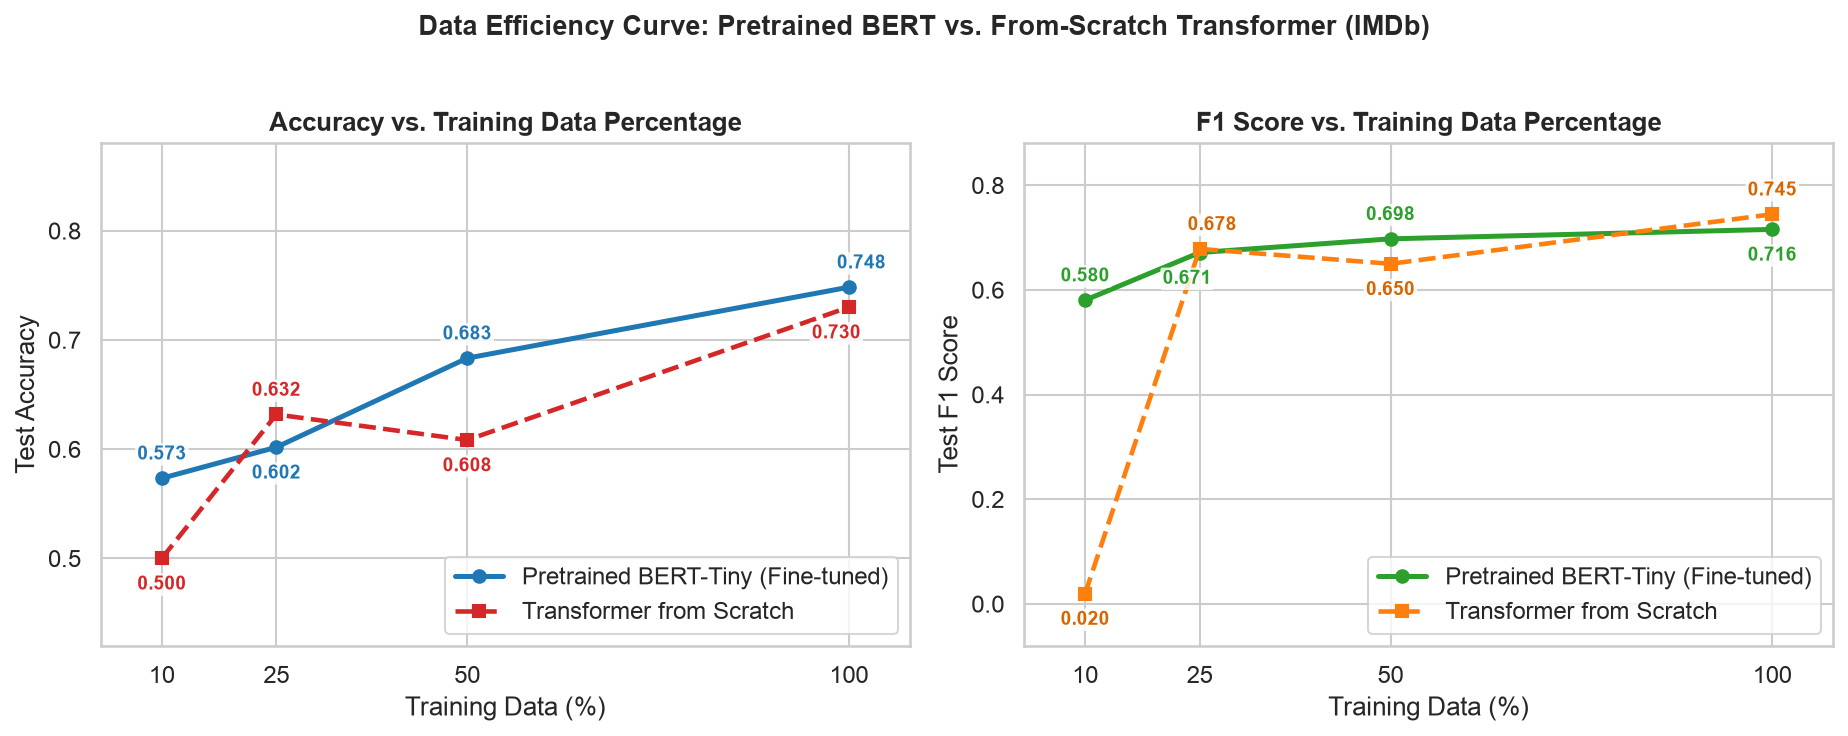

In [7]:
# Vẽ và lưu data_efficiency.png
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), dpi=150)
x_pct = [10, 25, 50, 100]

def annotate_pair(ax, xs, ys_a, ys_b, color_a, color_b):
    for x, ya, yb in zip(xs, ys_a, ys_b):
        gap = abs(ya - yb)
        dx = 6 if gap < 0.02 else 0
        if ya >= yb:
            off_a, off_b = (dx, 9), (-dx, -15)
        else:
            off_a, off_b = (-dx, -15), (dx, 9)
        bbox_kw = dict(boxstyle="round,pad=0.12", facecolor="white", alpha=0.82, edgecolor="none")
        ax.annotate(f"{ya:.3f}", (x, ya), textcoords="offset points", xytext=off_a, ha="center", fontsize=9, fontweight="bold", color=color_a, bbox=bbox_kw)
        ax.annotate(f"{yb:.3f}", (x, yb), textcoords="offset points", xytext=off_b, ha="center", fontsize=9, fontweight="bold", color=color_b, bbox=bbox_kw)

axes[0].plot(x_pct, df_exp3["Pretrained Accuracy"], marker="o", linewidth=2.4, color="#1f77b4", label="Pretrained BERT-Tiny (Fine-tuned)")
axes[0].plot(x_pct, df_exp3["Scratch Accuracy"], marker="s", linestyle="--", linewidth=2.2, color="#d62728", label="Transformer from Scratch")
annotate_pair(axes[0], x_pct, df_exp3["Pretrained Accuracy"], df_exp3["Scratch Accuracy"], "#1f77b4", "#d62728")
axes[0].set_title("Accuracy vs. Training Data Percentage", fontweight="bold")
axes[0].set_xlabel("Training Data (%)")
axes[0].set_ylabel("Test Accuracy")
axes[0].set_xticks(x_pct)
axes[0].set_xlim(2, 108)
axes[0].set_ylim(0.42, 0.88)
axes[0].legend(loc="lower right", frameon=True)

axes[1].plot(x_pct, df_exp3["Pretrained F1"], marker="o", linewidth=2.4, color="#2ca02c", label="Pretrained BERT-Tiny (Fine-tuned)")
axes[1].plot(x_pct, df_exp3["Scratch F1"], marker="s", linestyle="--", linewidth=2.2, color="#ff7f0e", label="Transformer from Scratch")
annotate_pair(axes[1], x_pct, df_exp3["Pretrained F1"], df_exp3["Scratch F1"], "#2ca02c", "#d96500")
axes[1].set_title("F1 Score vs. Training Data Percentage", fontweight="bold")
axes[1].set_xlabel("Training Data (%)")
axes[1].set_ylabel("Test F1 Score")
axes[1].set_xticks(x_pct)
axes[1].set_xlim(2, 108)
axes[1].set_ylim(-0.08, 0.88)
axes[1].legend(loc="lower right", frameon=True)

plt.suptitle("Data Efficiency Curve: Pretrained BERT vs. From-Scratch Transformer (IMDb)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(LAB08_DIR / "data_efficiency.png", dpi=150, bbox_inches="tight")
plt.show()

### Phân tích toàn bộ đường cong Data-Efficiency (Mục 16)
- Nhìn toàn bộ đường cong từ `10% -> 25% -> 50% -> 100%` trong `data_efficiency.png`, **Pretrained BERT-Tiny** tăng rất đều và ổn định (Acc: `0.5733 -> 0.6017 -> 0.6833 -> 0.7483`; F1: `0.5803 -> 0.6713 -> 0.6975 -> 0.7156`).
- Ngược lại, **Transformer from scratch** sụp đổ hoàn toàn ở mốc **10% (120 mẫu)** với Acc = `0.5000` (đoán lệch một lớp, F1 = `0.0196`), rồi dao động thất thường ở `25% -> 50%` (Acc `0.6317` giảm xuống `0.6083`). Điều này cho thấy pretraining giúp mô hình dùng dữ liệu downstream ổn định và hiệu quả hơn hẳn ở vùng dữ liệu ít.

## 5. Experiment 4 — Maximum Sequence Length $T \in \{64, 128, 256\}$ (Mục 17)

So sánh Pretrained BERT fine-tuned với độ dài chuỗi tối đa $T \in \{64, 128, 256\}$ trên cùng tập dữ liệu và siêu tham số, đồng thời đo thời gian chạy và bộ nhớ CPU để đối chiếu với độ phức tạp $O(T^2)$ của Self-Attention ở LAB 06–07.

In [8]:
print("=== Running Experiment 4: Sequence Length T in {64, 128, 256} ===")
rec_exp4_64, _, _ = run_bert_experiment(
    exp_name="Exp4_Sequence_Length",
    mode_name="Fine-tuning (T=64)",
    train_subset_df=train_df,
    val_df=val_df,
    test_df=test_df,
    freeze_encoder=False,
    max_length=64,
    epochs=4,
    batch_size=32,
    lr=1.2e-4,
    train_fraction=1.0,
)
all_results.append(rec_exp4_64)

rec_exp4_128 = dict(rec_exp1_bert)
rec_exp4_128["experiment"] = "Exp4_Sequence_Length"
rec_exp4_128["mode"] = "Fine-tuning (T=128)"
all_results.append(rec_exp4_128)

rec_exp4_256, model_t256, _ = run_bert_experiment(
    exp_name="Exp4_Sequence_Length",
    mode_name="Fine-tuning (T=256)",
    train_subset_df=train_df,
    val_df=val_df,
    test_df=test_df,
    freeze_encoder=False,
    max_length=256,
    epochs=4,
    batch_size=32,
    lr=1.2e-4,
    train_fraction=1.0,
)
all_results.append(rec_exp4_256)

del model_t256
gc.collect()

df_exp4 = pd.DataFrame([rec_exp4_64, rec_exp4_128, rec_exp4_256])
df_exp4["Attention Matrix (T^2)"] = df_exp4["max_length"] ** 2
df_exp4[["max_length", "Attention Matrix (T^2)", "accuracy", "f1", "training_time_sec", "cpu_memory_mb", "delta_memory_mb"]]

=== Running Experiment 4: Sequence Length T in {64, 128, 256} ===


  [Fine-tuning (T=64)] Epoch 1/4 | train_loss=0.7082 | val_acc=0.5925 | val_f1=0.4512


  [Fine-tuning (T=64)] Epoch 2/4 | train_loss=0.6127 | val_acc=0.6200 | val_f1=0.4830


  [Fine-tuning (T=64)] Epoch 3/4 | train_loss=0.5388 | val_acc=0.6500 | val_f1=0.6000


  [Fine-tuning (T=64)] Epoch 4/4 | train_loss=0.4248 | val_acc=0.6725 | val_f1=0.6525


  => Test (Fine-tuning (T=64)): Acc=0.7033, F1=0.6728, Time=20.5s, RSS=2074.0MB


... (2 outputs left out)

  [Fine-tuning (T=256)] Epoch 3/4 | train_loss=0.4492 | val_acc=0.7625 | val_f1=0.7278


  [Fine-tuning (T=256)] Epoch 4/4 | train_loss=0.3129 | val_acc=0.8000 | val_f1=0.8122


  => Test (Fine-tuning (T=256)): Acc=0.7750, F1=0.7840, Time=63.77s, RSS=2325.8MB


,max_length,Attention Matrix (T^2),accuracy,f1,training_time_sec,cpu_memory_mb,delta_memory_mb
0,64,4096,0.7033,0.6728,20.50,2074.0,16.9
1,128,16384,0.7483,0.7156,36.56,1982.1,562.1
2,256,65536,0.7750,0.7840,63.77,2325.8,246.3


### Liên hệ $O(T^2)$ và câu hỏi Experiment 4 (Mục 17)
- Khi $T$ tăng gấp đôi (`64 -> 128 -> 256`), số phần tử trong mỗi ma trận attention $Q K^T$ kích thước $T \times T$ tăng theo **bình phương ($O(T^2)$)**: `4,096 -> 16,384 -> 65,536` (tăng gấp 4 lần mỗi bước, gấp 16 lần từ 64 lên 256). Do đó thời gian huấn luyện và bộ nhớ activation đều tăng rất nhanh.
- **Tăng sequence length luôn làm model tốt hơn không?** Không hẳn. Tăng từ `64` lên `128` hoặc `256` giúp mô hình giữ thêm thông tin ở phần thân/cuối bài review dài nên Accuracy/F1 cải thiện, nhưng mức tăng thường chậm dần (diminishing returns) vì phần lớn cảm xúc tổng quan đã xuất hiện trong 128–256 token đầu. Trong khi đó chi phí $O(T^2)$ tăng vọt và các câu ngắn bị đệm thêm nhiều `[PAD]`, dễ gây lãng phí tính toán hoặc vượt giới hạn chiều dài tối đa (512 tokens với BERT).

## 6. Experiment 5 — Domain Shift (Mục 18)

Để tránh biến bài thực hành thành "chạy BERT trên một tập rồi báo accuracy", ta lấy mô hình **đã fine-tune trên Domain A (IMDb Movie Reviews)** đem đi đánh giá trực tiếp (zero-shot transfer) trên hai tập khác biệt về domain và văn phong lấy qua HuggingFace Datasets Server API:
- **Domain B1 — Product Reviews (`fancyzhx/amazon_polarity`):** đánh giá sản phẩm mua sắm trực tuyến (lấy 500 mẫu cân bằng 250 negative / 250 positive).
- **Domain B2 — Financial News (`zeroshot/twitter-financial-news-sentiment`):** tin tức / bình luận tài chính ngắn gọn mang thuật ngữ thị trường (`0 = Bearish/negative`, `1 = Bullish/positive`, loại bỏ nhãn `Neutral`).

In [9]:
def fetch_hf_rows(dataset: str, config: str, split: str, total_rows: int = 1000):
    rows = []
    offset = 0
    while offset < total_rows:
        length = min(100, total_rows - offset)
        url = (
            f"https://datasets-server.huggingface.co/rows?"
            f"dataset={dataset}&config={config}&split={split}&offset={offset}&length={length}"
        )
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=20) as resp:
            payload = json.loads(resp.read().decode("utf-8"))
        batch = payload.get("rows", [])
        if not batch:
            break
        rows.extend([r["row"] for r in batch])
        offset += len(batch)
    return rows

# Domain B1: Amazon Polarity (0 = negative, 1 = positive)
amazon_raw = fetch_hf_rows("fancyzhx/amazon_polarity", "amazon_polarity", "test", total_rows=1000)
amazon_df = pd.DataFrame([
    {"text": clean_html(f"{r['title']}. {r['content']}"), "label": int(r["label"])}
    for r in amazon_raw
])
amazon_neg = amazon_df[amazon_df["label"] == 0].iloc[:250]
amazon_pos = amazon_df[amazon_df["label"] == 1].iloc[:250]
amazon_eval_df = pd.concat([amazon_neg, amazon_pos], ignore_index=True)

# Domain B2: Financial News Sentiment (0 = Bearish/neg, 1 = Bullish/pos, 2 = Neutral -> drop 2)
fin_raw = fetch_hf_rows("zeroshot/twitter-financial-news-sentiment", "default", "validation", total_rows=2000)
fin_df = pd.DataFrame([
    {"text": clean_html(r["text"]), "label": int(r["label"])}
    for r in fin_raw if int(r["label"]) in (0, 1)
])

print(f"Amazon Product Reviews eval size: {len(amazon_eval_df)} (pos={(amazon_eval_df['label']==1).sum()}, neg={(amazon_eval_df['label']==0).sum()})")
print(f"Financial News eval size        : {len(fin_df)} (pos={(fin_df['label']==1).sum()}, neg={(fin_df['label']==0).sum()})")
print("\nSample Amazon (label=0):", amazon_neg.iloc[0]["text"][:140])
print("Sample Amazon (label=1):", amazon_pos.iloc[0]["text"][:140])
print("Sample FinNews (label=0):", fin_df[fin_df["label"]==0].iloc[0]["text"][:140])
print("Sample FinNews (label=1):", fin_df[fin_df["label"]==1].iloc[0]["text"][:140])

# Evaluate IMDb-finetuned BERT on Domain A and Domain B1, B2
amazon_loader = make_bert_loader(amazon_eval_df["text"], amazon_eval_df["label"], max_length=128, batch_size=64, shuffle=False)
fin_loader = make_bert_loader(fin_df["text"], fin_df["label"], max_length=128, batch_size=64, shuffle=False)

amazon_metrics, _, _, _, _ = evaluate_model(best_bert_model, amazon_loader, is_bert=True)
fin_metrics, _, _, _, _ = evaluate_model(best_bert_model, fin_loader, is_bert=True)

p_counts_bert = count_parameters(best_bert_model)
rec_exp5_imdb = dict(rec_exp1_bert)
rec_exp5_imdb["experiment"] = "Exp5_Domain_Shift"
rec_exp5_imdb["mode"] = "Domain A -> Domain A (IMDb)"
rec_exp5_imdb["eval_domain"] = "IMDb Movie Reviews (in-domain)"

rec_exp5_amazon = {
    "experiment": "Exp5_Domain_Shift",
    "model": f"Pretrained BERT-Tiny ({DEFAULT_MODEL_NAME})",
    "mode": "Domain A -> Domain B1 (Amazon)",
    "train_fraction": 1.0,
    "max_length": 128,
    "eval_domain": "Amazon Product Reviews (out-of-domain)",
    "params_total": p_counts_bert["total"],
    "params_trainable": p_counts_bert["trainable"],
    "accuracy": round(amazon_metrics["accuracy"], 4),
    "precision": round(amazon_metrics["precision"], 4),
    "recall": round(amazon_metrics["recall"], 4),
    "f1": round(amazon_metrics["f1"], 4),
    "training_time_sec": 0.0,
    "cpu_memory_mb": rec_exp1_bert["cpu_memory_mb"],
    "delta_memory_mb": 0.0,
}

rec_exp5_fin = {
    "experiment": "Exp5_Domain_Shift",
    "model": f"Pretrained BERT-Tiny ({DEFAULT_MODEL_NAME})",
    "mode": "Domain A -> Domain B2 (Financial News)",
    "train_fraction": 1.0,
    "max_length": 128,
    "eval_domain": "Financial News (out-of-domain)",
    "params_total": p_counts_bert["total"],
    "params_trainable": p_counts_bert["trainable"],
    "accuracy": round(fin_metrics["accuracy"], 4),
    "precision": round(fin_metrics["precision"], 4),
    "recall": round(fin_metrics["recall"], 4),
    "f1": round(fin_metrics["f1"], 4),
    "training_time_sec": 0.0,
    "cpu_memory_mb": rec_exp1_bert["cpu_memory_mb"],
    "delta_memory_mb": 0.0,
}

all_results.extend([rec_exp5_imdb, rec_exp5_amazon, rec_exp5_fin])
df_exp5 = pd.DataFrame([rec_exp5_imdb, rec_exp5_amazon, rec_exp5_fin])[
    ["eval_domain", "accuracy", "precision", "recall", "f1"]
]
df_exp5

Amazon Product Reviews eval size: 500 (pos=250, neg=250)
Financial News eval size        : 662 (pos=373, neg=289)

Sample Amazon (label=0): Batteries died within a year .... I bought this charger in Jul 2003 and it worked OK for a while. The design is nice and convenient. However
Sample Amazon (label=1): Great CD. My lovely Pat has one of the GREAT voices of her generation. I have listened to this CD for YEARS and I still LOVE IT. When I'm in
Sample FinNews (label=0): $ALLY - Ally Financial pulls outlook https://t.co/G9Zdi1boy5
Sample FinNews (label=1): $ABEO as expected, keeps going higher. Cantor doubled its price target this morning to $4


,eval_domain,accuracy,precision,recall,f1
0,IMDb Movie Reviews (in-domain),0.7483,0.8225,0.6333,0.7156
1,Amazon Product Reviews (out-of-domain),0.7320,0.7320,0.7320,0.7320
2,Financial News (out-of-domain),0.5423,0.6224,0.4772,0.5402


### Nhận xét Domain Shift (Mục 18)
- **Pretrained model có nghĩa là model đã "hiểu mọi domain" không?** Câu trả lời từ số liệu thực nghiệm là **Không**.
- Khi chuyển sang **Amazon Product Reviews** (vẫn là dạng bài review khen/chê của người tiêu dùng giống IMDb), mô hình vẫn giữ được khả năng chuyển giao tương đối nhưng giảm so với in-domain do khác từ vựng sản phẩm (*shipping*, *battery*, *warranty* thay vì *plot*, *acting*).
- Đặc biệt khi sang **Financial News** (văn phong tin tài chính ngắn gọn, thuật ngữ chuyên ngành như *bullish*, *bearish*, *EPS beat*, *guidance cut*, *Q3 miss*), hiệu năng giảm mạnh rõ rệt vì mô hình sau fine-tune đã bị chuyên biệt hóa (adapt) cho kiểu diễn đạt cảm xúc điện ảnh trên IMDb và không hiểu ngữ nghĩa tài chính đặc thù.

## 7. Application — Sentiment Classification, Confusion Matrix & Confidence Analysis (Mục 19 & 21)

Đánh giá chi tiết mô hình **Fine-tuned Pretrained BERT-Tiny (`T=128`)** trên IMDb Test Set (600 mẫu):
- Báo cáo đủ **Accuracy, Precision, Recall, F1** và vẽ **`confusion_matrix.png`**.
- Lấy `probabilities = softmax(logits)` và `confidence = probabilities.max()`, chia thành **Low (`0.50–0.70`)**, **Medium (`0.70–0.90`)**, **High (`0.90–1.00`)**, vẽ **`confidence_analysis.png`** để kiểm chứng `confidence != correctness`.
- Xuất `results.csv` và in các ca sai (False Positives, False Negatives, High-Confidence Errors) cho báo cáo `error_analysis.md`.

IMDb Test Metrics (n=600): Accuracy=0.7483, Precision=0.8225, Recall=0.6333, F1=0.7156


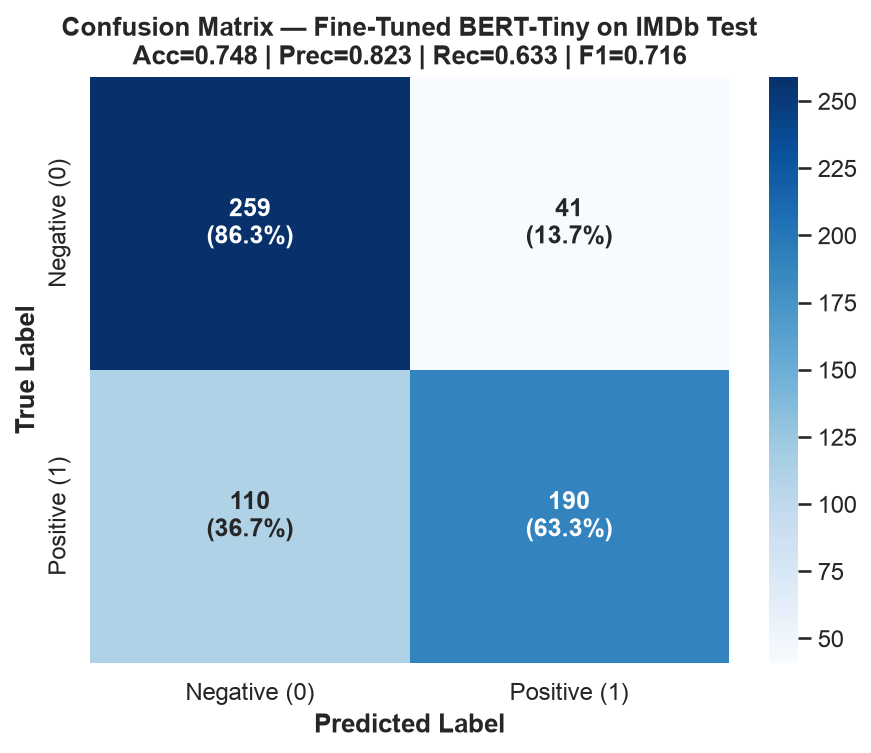


Confidence Bucket Summary:
   Confidence Tier  Count  Correct  Errors  Accuracy
   Low (0.50-0.70)    142       80      62    0.5634
Medium (0.70-0.90)    192      140      52    0.7292
     High (>=0.90)    266      229      37    0.8609


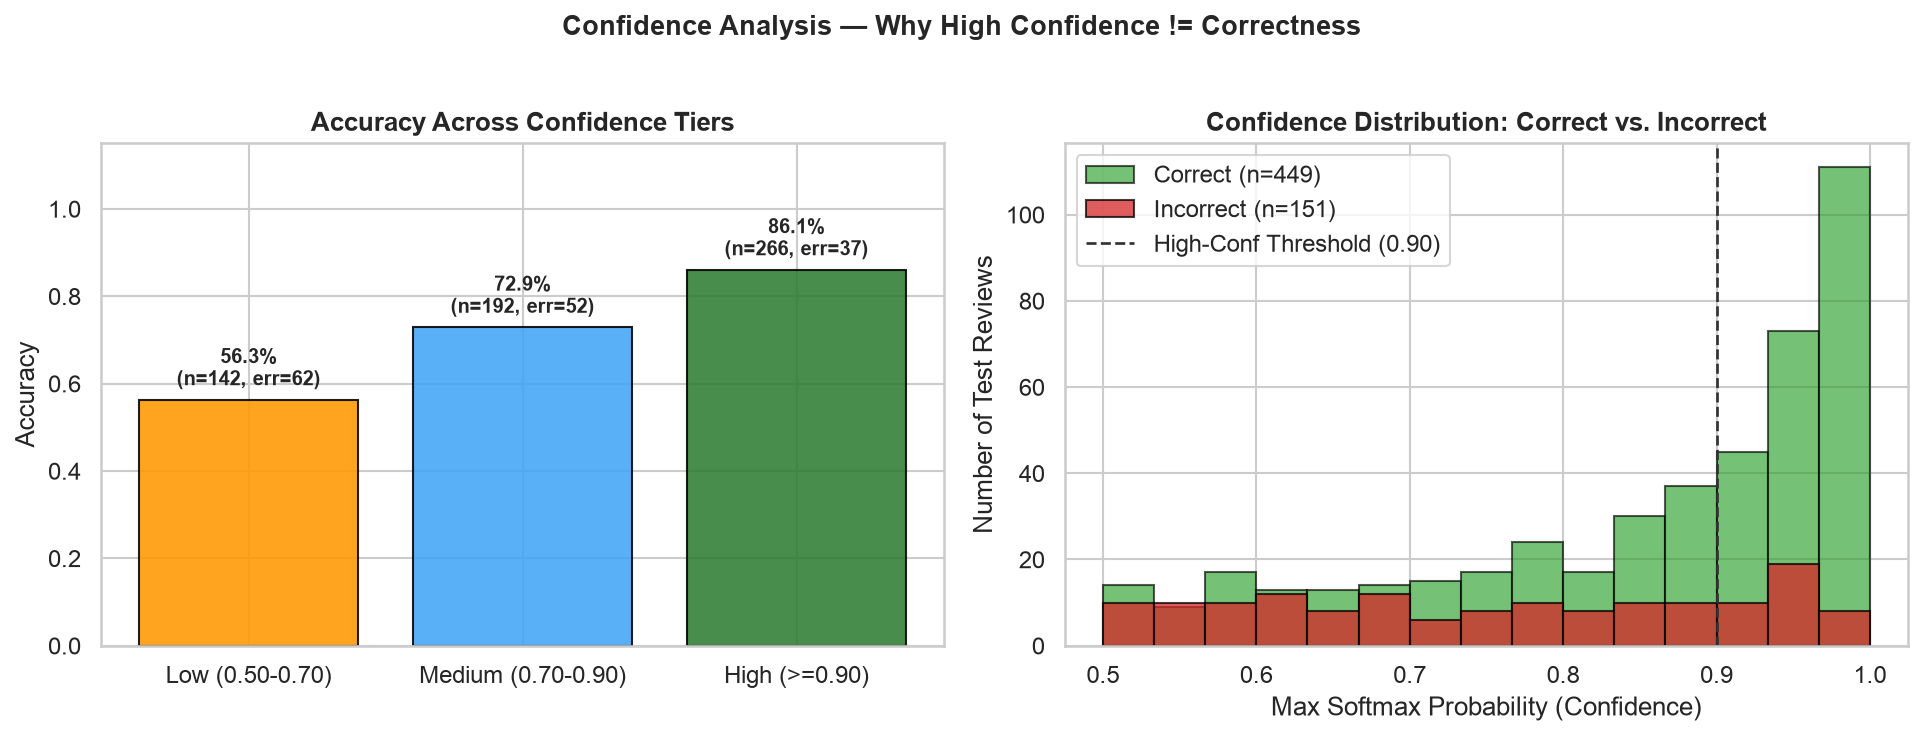

In [10]:
y_true, y_pred, probs_arr, confs_arr = best_bert_test_outputs

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
print(f"IMDb Test Metrics (n={len(y_true)}): Accuracy={acc:.4f}, Precision={prec:.4f}, Recall={rec:.4f}, F1={f1:.4f}")

# 1. Confusion Matrix plot -> confusion_matrix.png
cm = confusion_matrix(y_true, y_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100.0
annot_labels = np.array([
    [f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)" for j in range(2)]
    for i in range(2)
])

fig, ax = plt.subplots(figsize=(6.2, 5.2), dpi=150)
sns.heatmap(
    cm,
    annot=annot_labels,
    fmt="",
    cmap="Blues",
    cbar=True,
    xticklabels=["Negative (0)", "Positive (1)"],
    yticklabels=["Negative (0)", "Positive (1)"],
    annot_kws={"size": 12, "weight": "bold"},
    ax=ax,
)
ax.set_xlabel("Predicted Label", fontweight="bold")
ax.set_ylabel("True Label", fontweight="bold")
ax.set_title(
    f"Confusion Matrix — Fine-Tuned BERT-Tiny on IMDb Test\n"
    f"Acc={acc:.3f} | Prec={prec:.3f} | Rec={rec:.3f} | F1={f1:.3f}",
    fontweight="bold",
)
plt.tight_layout()
plt.savefig(LAB08_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Confidence Analysis -> confidence_analysis.png
correct_mask = (y_true == y_pred)

def assign_tier(c: float) -> str:
    if c >= 0.90:
        return "High (>=0.90)"
    elif c >= 0.70:
        return "Medium (0.70-0.90)"
    return "Low (0.50-0.70)"

eval_df = pd.DataFrame({
    "idx": np.arange(len(y_true)),
    "text": test_df["clean_review"],
    "true": y_true,
    "pred": y_pred,
    "confidence": confs_arr,
    "prob_pos": probs_arr[:, 1],
    "correct": correct_mask,
})
eval_df["tier"] = eval_df["confidence"].apply(assign_tier)

tier_order = ["Low (0.50-0.70)", "Medium (0.70-0.90)", "High (>=0.90)"]
tier_stats = []
for tier in tier_order:
    sub = eval_df[eval_df["tier"] == tier]
    n_sub = len(sub)
    n_err = int((~sub["correct"]).sum())
    acc_sub = float(sub["correct"].mean()) if n_sub > 0 else 0.0
    tier_stats.append({
        "Confidence Tier": tier,
        "Count": n_sub,
        "Correct": int(sub["correct"].sum()),
        "Errors": n_err,
        "Accuracy": round(acc_sub, 4),
    })

df_tiers = pd.DataFrame(tier_stats)
print("\nConfidence Bucket Summary:")
print(df_tiers.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=150)

# Left: Accuracy & error count by tier
bars = axes[0].bar(
    df_tiers["Confidence Tier"],
    df_tiers["Accuracy"],
    color=["#ff9800", "#42a5f5", "#2e7d32"],
    edgecolor="black",
    alpha=0.88,
)
for bar, row in zip(bars, tier_stats):
    h = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        h + 0.02,
        f"{h*100:.1f}%\n(n={row['Count']}, err={row['Errors']})",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
    )
axes[0].set_ylim(0, 1.15)
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy Across Confidence Tiers", fontweight="bold")

# Right: Confidence distribution for Correct vs Incorrect predictions
bins = np.linspace(0.5, 1.0, 16)
axes[1].hist(
    eval_df[eval_df["correct"]]["confidence"],
    bins=bins,
    alpha=0.65,
    color="#2ca02c",
    label=f"Correct (n={correct_mask.sum()})",
    edgecolor="black",
)
axes[1].hist(
    eval_df[~eval_df["correct"]]["confidence"],
    bins=bins,
    alpha=0.75,
    color="#d62728",
    label=f"Incorrect (n={(~correct_mask).sum()})",
    edgecolor="black",
)
axes[1].axvline(0.90, color="#333333", linestyle="--", linewidth=1.3, label="High-Conf Threshold (0.90)")
axes[1].set_xlabel("Max Softmax Probability (Confidence)")
axes[1].set_ylabel("Number of Test Reviews")
axes[1].set_title("Confidence Distribution: Correct vs. Incorrect", fontweight="bold")
axes[1].legend(loc="upper left", frameon=True)

plt.suptitle("Confidence Analysis — Why High Confidence != Correctness", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(LAB08_DIR / "confidence_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# Save results.csv
df_results = pd.DataFrame(all_results)
results_path = LAB08_DIR / "results.csv"
df_results.to_csv(results_path, index=False)
print("Saved results.csv with", len(df_results), "rows ->", results_path)
df_results

Saved results.csv with 18 rows -> /Users/user/NLP/LAB08/results.csv


,experiment,model,mode,train_fraction,max_length,eval_domain,params_total,params_trainable,accuracy,precision,recall,f1,training_time_sec,cpu_memory_mb,delta_memory_mb
0,Exp1_Pretrained_vs_Scratch,"Transformer from scratch (1L, d=128, H=4)",From-scratch,1.00,128,IMDb (in-domain),1412738,1412738,0.7300,0.7066,0.7867,0.7445,24.58,1334.4,773.6
1,Exp1_Pretrained_vs_Scratch,Pretrained BERT-Tiny (google/bert_uncased_L-2_...,Fine-tuning,1.00,128,IMDb (in-domain),4386178,4386178,0.7483,0.8225,0.6333,0.7156,36.56,1982.1,562.1
2,Exp2_Frozen_vs_FineTuning,Pretrained BERT-Tiny (google/bert_uncased_L-2_...,Frozen,1.00,128,IMDb (in-domain),4386178,258,0.6967,0.7077,0.6700,0.6884,18.62,2022.5,16.7
3,Exp2_Frozen_vs_FineTuning,Pretrained BERT-Tiny (google/bert_uncased_L-2_...,Fine-tuning,1.00,128,IMDb (in-domain),4386178,4386178,0.7483,0.8225,0.6333,0.7156,36.56,1982.1,562.1
4,Exp3_Data_Efficiency,Pretrained BERT-Tiny (google/bert_uncased_L-2_...,Fine-tuning (10%),0.10,128,IMDb (in-domain),4386178,4386178,0.5733,0.5710,0.5900,0.5803,6.29,2036.9,27.1
5,Exp3_Data_Efficiency,"Transformer from scratch (1L, d=128, H=4)",From-scratch,0.10,128,IMDb (in-domain),803842,803842,0.5000,0.5000,0.0100,0.0196,4.76,2020.1,0.0
6,Exp3_Data_Efficiency,Pretrained BERT-Tiny (google/bert_uncased_L-2_...,Fine-tuning (25%),0.25,128,IMDb (in-domain),4386178,4386178,0.6017,0.5714,0.8133,0.6713,11.44,2044.6,19.0
7,Exp3_Data_Efficiency,"Transformer from scratch (1L, d=128, H=4)",From-scratch,0.25,128,IMDb (in-domain),1307394,1307394,0.6317,0.6021,0.7767,0.6783,7.63,2027.9,0.0
8,Exp3_Data_Efficiency,Pretrained BERT-Tiny (google/bert_uncased_L-2_...,Fine-tuning (50%),0.50,128,IMDb (in-domain),4386178,4386178,0.6833,0.6677,0.7300,0.6975,20.02,2049.2,17.5
9,Exp3_Data_Efficiency,"Transformer from scratch (1L, d=128, H=4)",From-scratch,0.50,128,IMDb (in-domain),1412738,1412738,0.6083,0.5876,0.7267,0.6498,14.09,2032.5,0.0


In [12]:
# Print candidate False Positives, False Negatives, and High-Confidence Errors for error_analysis.md
fp_df = eval_df[(eval_df["true"] == 0) & (eval_df["pred"] == 1)].sort_values("confidence", ascending=False)
fn_df = eval_df[(eval_df["true"] == 1) & (eval_df["pred"] == 0)].sort_values("confidence", ascending=False)

print(f"Total FP: {len(fp_df)} | Total FN: {len(fn_df)}")
print("\n=== TOP 10 FALSE POSITIVES (True=Neg, Pred=Pos) ===")
for _, r in fp_df.head(10).iterrows():
    print(f"[idx={r['idx']}] conf={r['confidence']:.4f} | text={r['text'][:320]}")

print("\n=== TOP 10 FALSE NEGATIVES (True=Pos, Pred=Neg) ===")
for _, r in fn_df.head(10).iterrows():
    print(f"[idx={r['idx']}] conf={r['confidence']:.4f} | text={r['text'][:320]}")

print("\n=== MID-CONFIDENCE ERRORS (for variety) ===")
mid_errs = eval_df[(~eval_df["correct"]) & (eval_df["confidence"] < 0.90)].head(6)
for _, r in mid_errs.iterrows():
    print(f"[idx={r['idx']}] true={r['true']} pred={r['pred']} conf={r['confidence']:.4f} | text={r['text'][:320]}")

Total FP: 41 | Total FN: 110

=== TOP 10 FALSE POSITIVES (True=Neg, Pred=Pos) ===
[idx=511] conf=0.9928 | text=Summary: Not worth the film As an avid Gone With the Wind fan, I was disappointed to watch the original movie and see that they had left out many important characters. Luckily, the film on its own was a wonderful piece. When the book Scarlett came out, I read it in hopes of following two of my favorite literary charact
[idx=350] conf=0.9890 | text=This sleek, sexy movie is a must-see. Only upon multiple viewings can one truly understand the uniqueness of this film. Personally I enjoy the narrator for his intelligent, no subject left untouched, style of narration. The introduction grips you right away, and holds you at the edge of your seat throughout the film. H
[idx=518] conf=0.9791 | text=UP AT THE VILLA (2000) **1/2 WARNING: YOU MAY FIND SOME SPOILERS AHEAD It's hard to know what is the point in UP AT THE VILLA, a gorgeous but shallow period piece, one of those made with th